In [3]:
import pandas as pd 
import seaborn as sns
import duckdb
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [44]:
%pip install seaborn
%pip install Plotly

Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 25.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [Plotly]2m1/2 [Plotly]
Note: you may need to restart the kernel to use updated packages.


In [7]:
olympics = pd.read_csv('olympics.csv')

In [8]:
olympics.columns #a function in pandas

Index(['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games',
       'Year', 'Season', 'City', 'Sport', 'Event', 'Medal'],
      dtype='str')

In [13]:
athletes = duckdb.sql ("""SELECT * FROM olympics 
                        WHERE Games = '2016 Summer' AND SEX = 'M'    
                        AND (Sport = 'Basketball' OR Sport = 'Hockey' OR Sport = 'Gymnastics')""").df()


In [14]:
athletes.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Individual All-Around,NaN
1,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Floor Exercise,NaN
2,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Parallel Bars,NaN
3,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Horizontal Bar,NaN
4,51,Nstor Abad Sanjun,M,23.0,167.0,64.0,Spain,ESP,2016 Summer,2016,Summer,Rio de Janeiro,Gymnastics,Gymnastics Men's Rings,NaN


<Axes: xlabel='Height', ylabel='Weight'>

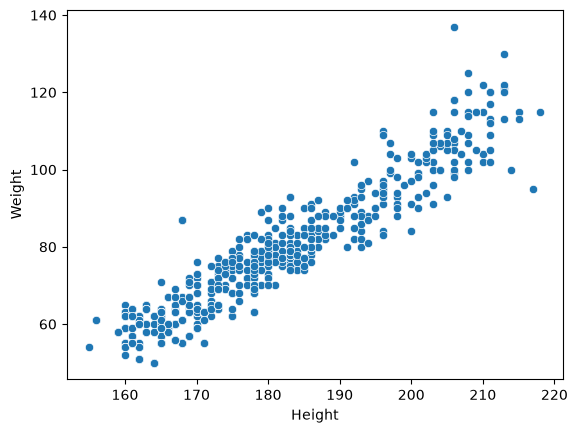

In [15]:
#Start by calling the basic scatterplot function in seaborn

sns.scatterplot(athletes, x = 'Height', y = 'Weight') #reference library, function with parameters dataset and x/y axis titles

<Axes: xlabel='Height', ylabel='Weight'>

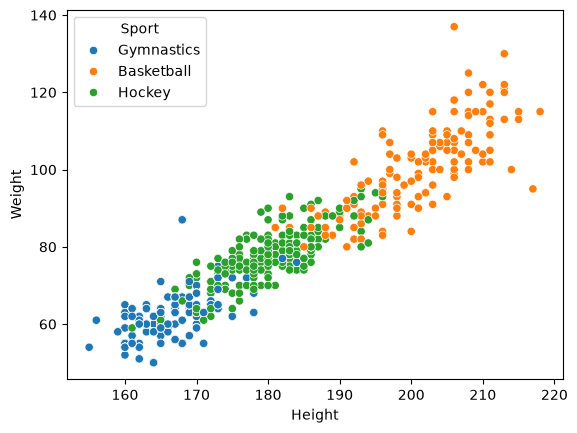

In [ ]:
sns.scatterplot(athletes, x = 'Height', y = 'Weight', hue = 'Sport') #reference library, function with parameter dataset and x/y axis title
#hue parameter allows for grouping of subsets 

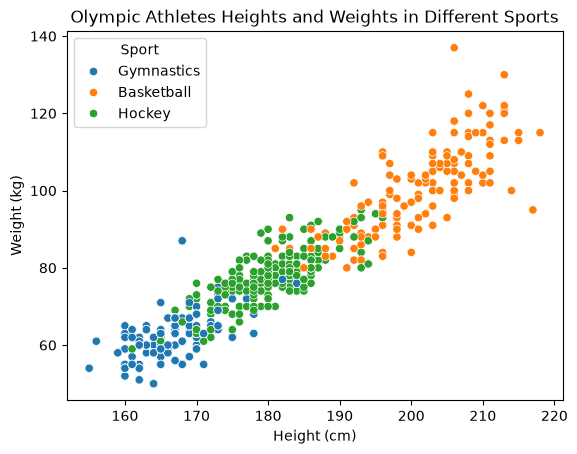

In [ ]:
sns.scatterplot(athletes, x = 'Height', y = 'Weight', hue = 'Sport')
plt.xlabel('Height (cm)') #label function from matplotlib --> (matplotlib does a lot more than seaborn)
plt.ylabel('Weight (kg)') #same as above
plt.title('Olympic Athletes Heights and Weights in Different Sports')
plt.show() #plt.show() allows us to display the whole scatterplot 

In [18]:
#Line Plots 

#manipulating out dataset
#to display data in line plot form 

athletes_line  = duckdb.sql("""SELECT Year, AVG(Height) AS AvgHeight
                            FROM olympics
                            WHERE Season = 'Summer' AND Sport = 'Basketball'
                            GROUP BY Year
                            ORDER BY Year ASC"""
                            ).df()

In [19]:
#double check with the head() function 

athletes_line.head()

,Year,AvgHeight
0,1936,182.574074
1,1948,185.550725
2,1952,187.600000
3,1956,186.952941
4,1960,188.317708


<Axes: xlabel='Year', ylabel='AvgHeight'>

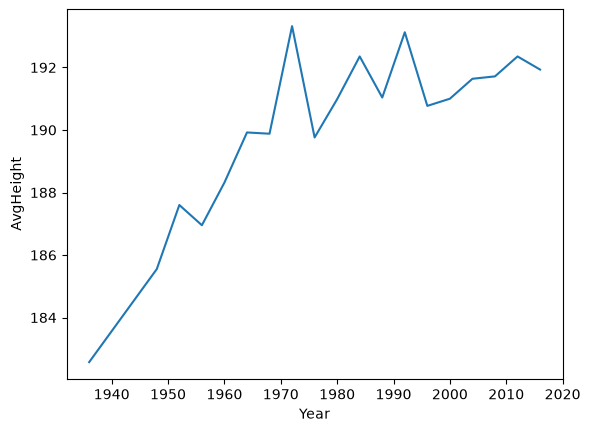

In [21]:
#graph using seaborn 

sns.lineplot(athletes_line, x = 'Year', y = 'AvgHeight')

<function matplotlib.pyplot.show(close=None, block=None)>

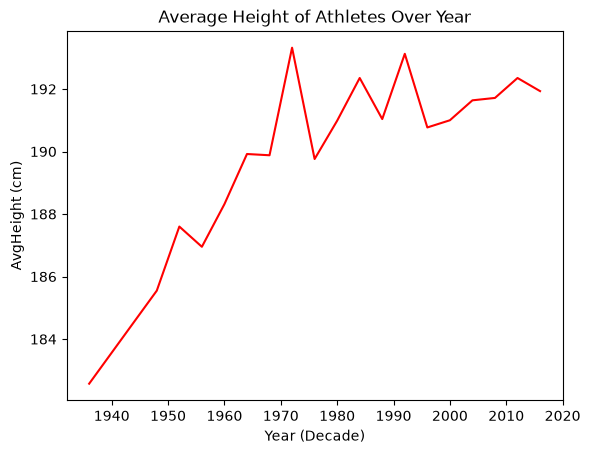

In [24]:
#A1 duplicate the above plot, add an appropriate tile, and appropriate y-axis label, changing the color of the line to something
#other than the default shade of blue 

sns.lineplot(athletes_line, x = 'Year', y = 'AvgHeight', color = 'red')
plt.xlabel('Year (Decade)')
plt.ylabel('AvgHeight (cm)')
plt.title('Average Height of Athletes Over Year')
plt.show


In [33]:
#Create a Histogram 
#A2

#Number of Gold Medals each country has earned in the 2012 Summer Olympics 

golds = duckdb.sql("""SELECT Team,  COUNT(*) as Golds
                        FROM olympics
                        WHERE Medal = 'Gold' AND Year = 2012
                        GROUP BY Team
                        ORDER BY Golds DESC
                        LIMIT 10""").df()

In [34]:
golds.head()

,Team,Golds
0,United States,139
1,Russia,50
2,China,50
3,Great Britain,46
4,Germany,43


<Axes: xlabel='Team', ylabel='Golds'>

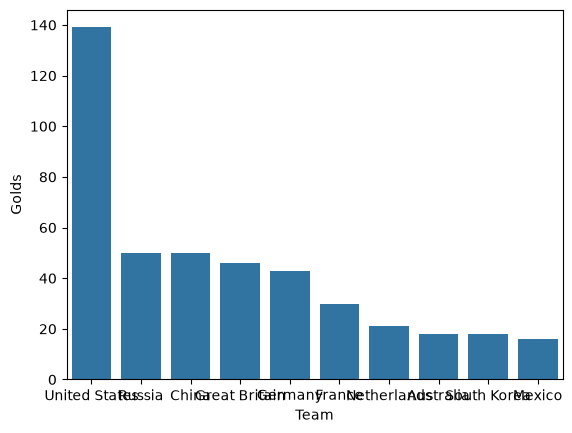

In [35]:
#call the barplot function in seaborn
sns.barplot(golds, x = 'Team', y = 'Golds')

<function matplotlib.pyplot.show(close=None, block=None)>

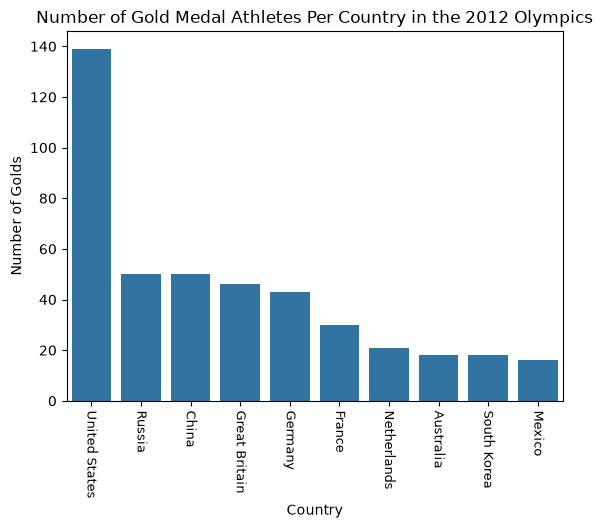

In [39]:
#Improvements 

sns.barplot(golds, x = 'Team', y = 'Golds')
plt.xticks(rotation = -90, fontsize = 9)
plt.xlabel('Country')
plt.ylabel('Number of Golds')
plt.title ('Number of Gold Medal Athletes Per Country in the 2012 Olympics')
plt.show

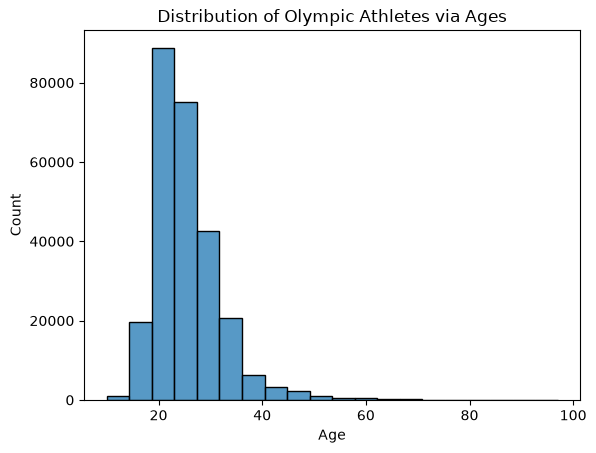

In [40]:
#We can also call a histogram function (histplot)

sns.histplot(olympics, x = 'Age', bins = 20)
plt.title('Distribution of Olympic Athletes via Ages')
plt.show()

In [41]:
#A3
#Filter the dataset to just the 100 meter dash from the 2016 Summer Olympics 
#Make a scatter plot of each of the athletes Height (X Axis) versus Weight (Y Axis)

#Use the hue parameter to change the color of the points based on the Medal Category
#Athletes who receive a Gold, Silver, or Bronze)

fastest = duckdb.sql ("""SELECT * FROM olympics
                      WHERE Games = '2016 Summer' AND SEX = 'M' AND Event LIKE '% 100 metres%'
                      AND Sport = 'Athletics'""").df()

fastest['Medal'] = fastest['Medal'].fillna("")

In [42]:
fastest.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,611,Mohammed Abukhousa,M,23.0,170.0,67.0,Palestine,PLE,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
1,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
2,804,Antoine Xavier Adams,M,27.0,180.0,79.0,Saint Kitts and Nevis,SKN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,
3,1421,Masbah Ahmmed,M,21.0,NaN,NaN,Bangladesh,BAN,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 100 metres,
4,1488,Harry Leslie Aikines-Aryeetey,M,27.0,180.0,87.0,Great Britain,GBR,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,Athletics Men's 4 x 100 metres Relay,


<function matplotlib.pyplot.show(close=None, block=None)>

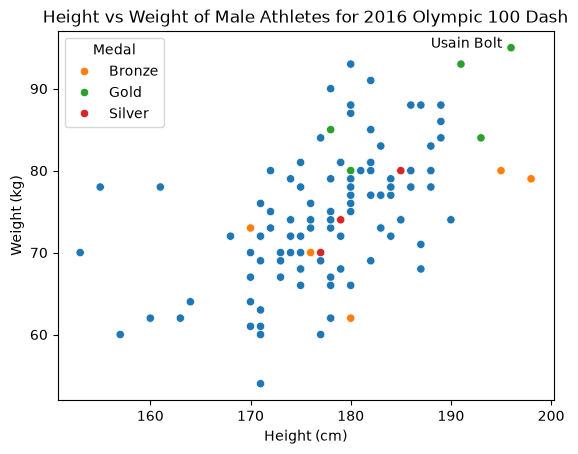

In [43]:
#Create the scatterplot
#Use sns data = fastest, x = 'Height', y = 'Weight', and hue = 'Medal'
sns.scatterplot(fastest, x = 'Height', y = 'Weight', hue = 'Medal')

#Add requested annotation to check accuracy (Usain Bolt)
plt.annotate(text = "Usain Bolt", xy = (188, 95))

plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Height vs Weight of Male Athletes for 2016 Olympic 100 Dash')
plt.show

In [45]:
#Utilize Plotly 
#Has its own syntax but is useful for dynamic and interactive visualizations

import plotly.express as px 



In [47]:
#Make a subset of the original olympics dataset and filter for 1992 Summer Games (Male Athletes) US Team, Basketball
dream_team = duckdb.sql("""SELECT * FROM olympics
                        WHERE Games = '1992 Summer' AND SEX = 'M' AND Sport = 'Basketball' AND Team = 'United States'""").df()

In [48]:
dream_team.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,7901,Charles Wade Barkley,M,29.0,198.0,114.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
1,11668,Larry Joe Bird,M,35.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
2,30009,Clyde Austin Drexler,M,30.0,200.0,101.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
3,33553,Patrick Aloysius Ewing,M,29.0,213.0,109.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold
4,55424,"Earvin ""Magic"" Johnson, Jr.",M,32.0,205.0,100.0,United States,USA,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Gold


In [51]:
#Make the Plotly Plot

fig = px.scatter(dream_team, x = 'Height', y = 'Weight', text = 'Name', width = 800, height = 500)
fig.update_layout(title = '1992 Dream Team Players Heights and Weights',
                  xaxis_title = 'Height (cm)',
                  yaxis_title = 'Weight (kg)')
fig.show()

